## 1. Problem, expected output and dataset source

The following three markdown cells are copied unchanged from the supplied dataset exploration notebook explains how oour final one-class detector uses these labels and how its box/class/confidence output differs from a location in GPS coordinates.


# QUESTION 1

Possible open-source datasets that are relevant to your research area.
We explored the following open source datasets for our MLEngine
* https://www.kaggle.com/datasets/muskanverma24/pothole-detection-dataset-yolov11-optimized
    * it has over 3900 images formatted for YOLO hence making it easily usable for
    training it also provides images used to train , to test and those that were valid
* https://www.kaggle.com/datasets/jee1oner/dashcam-pov-potholes-and-barricades-for-yolo26n
    * contains over 3400 images in YOLO format specifically for two classes potholes and barricade
* https://www.kaggle.com/datasets/sabidrahman/pothole-cracks-and-openmanhole
    * this dataset contains over 2700 images organized into training folders and validation folders detecting cracks, potholes and open manholes in roads


# QUESTION 2

For each dataset Identify variables that would serve as the expected output of our final application
** https://www.kaggle.com/datasets/muskanverma24/pothole-detection-dataset-yolov11-optimized
 *for this dataset the variable we identified was the pothole detection/location one using bounding box coordinates. If a pothole is detected the app identifies the potholes and its coordinates

 *** https://www.kaggle.com/datasets/jee1oner/dashcam-pov-potholes-and-barricades-for-yolo26n
    * the variable we identified in this dataset is the Hazard type classification - this dataset has two classes identifying road hazards as either pothole or barricade

** https://www.kaggle.com/datasets/sabidrahman/pothole-cracks-and-openmanhole
    * For this dataset the variable we identified was Category of road hazard the dataset categorises the road hazard as either pothole, crack or open manhole




# QUESTION 3

We chose this dataset * https://www.kaggle.com/datasets/muskanverma24/pothole-detection-dataset-yolov11-optimized  


We decided to go with this dataset  because for us the important thing is to identify the potholes and their coordinate/location which makes this dataset the best one applicable


since the model we're working on is a computer vision model and the dataset we've chosen contains images and labels of those images seperately, we're first going to form a single csv file by writing a pyhon script to contain the image names, image labels as well as specific columns present in each label i.e. class_id,x_center,y_center,width,height
in this case, some images may have different potholes and each having their own labels, so we'll have say class_id(1),... class_id(2)...

## 2. Dataset and labels

Source metadata is preserved in data/1/README.roboflow.txt and data/1/data.yaml (declared CC BY 4.0). YOLO annotations are class plus normalized center x/y and width/height. See the original [exploration notebook](pothole_detection_dataset_YOLOv11_optimized_Exploration.ipynb). Team: verify attribution and explain multiple label lines and structural NaN padding in the derived wide CSV.

## 3. EDA verification evidence

The following observations come from reproduced verification. Interpretations should state the consequence and limitation of each finding.

- Counts vary from 1–21 potholes/image; 1,767 images contain one annotated pothole. Per-split distributions are in [summary](reports/verification_2026-10-27/cleaned_v3_summary.json).
- 834 filename source groups; 385 span original splits and zero span v3 splits. These are filename groups, not guaranteed distinct scenes.
- Recorded cross-split pHash findings reproduce exactly: eight v2 pairs, zero v3 pairs at distance <=5. This does not prove complete scene independence.
- Zero empty labels in all v3 splits. Team: explain the limitation of having no empty-label negatives.
- Additional diagnostic: median box area is 2.832% of image area. Team: consider how object scale could affect detection, without claiming a subgroup score that was not measured.

![Reproduced cleaned-v3 EDA](reports/verification_2026-10-27/cleaned_v3_eda.png)

## 4. Cleaning and split decisions

The following existing cleaning notebook cells are copied unchanged, with newly executed outputs. WRITE_COPY=False. Original source: [cleaning notebook](notebooks/roadwatch_dataset_cleaning.ipynb). Full reproduced execution: [verification notebook](reports/audit/2026-10-27/verification/cleaning_reproduced.ipynb). The v2-to-v3 decision replay verifies the saved record, not the original human visual judgment. Team: explain each check and the five-group correction.


# RoadWatch AI: cleaning the pothole dataset
In this notebook, We go through the checks and split decisions used to prepare the pothole dataset, starting from `data/1` and verifying the final files in `data/cleaned`.

We use Pillow, ImageHash, NumPy and Matplotlib for the checks and plots. The paths are relative to the repository, so We can run the notebook from the project root or `notebooks/`.

We keep the original images and labels unchanged. Copying is disabled by default because the cleaned dataset already exists. We use the saved manifests to replay the recorded split decisions; the visual review itself is not automated.

The final v3 dataset contains **3,940 images, 10,111 boxes and 834 filename source groups**. The split is 3,196 images / 8,141 boxes for training, 375 / 1,097 for validation and 369 / 873 for testing. Below, We check these counts along with label validity and cross-split similarity.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv, hashlib, math, random, shutil
import numpy as np
from PIL import Image, ImageDraw
import imagehash
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/1/train/images').is_dir()), None)
assert ROOT is not None, 'Open this notebook inside the repository containing data/1.'
RAW = ROOT / 'data/1'
SPLITS = ('train', 'valid', 'test')
WRITE_COPY = False
OUTPUT = ROOT / 'data/cleaned_notebook'  # I keep this separate from data/cleaned
print('Repository:', ROOT.name)


Repository: SemProject_MLEngine


## 1. Exploring the data and pairing images with labels
We start by counting the images and labels in each original split. We match each image to a text file with the same filename stem, then check for missing labels, orphan labels and ambiguous names.

We also extract the part before `.rf.` as the filename source group. This lets me keep exported variants of the same named source together. Different source names can still refer to similar scenes, so We check that separately later.


In [2]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
records = []
pairing_errors = []
for split in SPLITS:
    images = sorted(p for p in (RAW / split / 'images').iterdir()
                    if p.suffix.lower() in EXTENSIONS)
    labels = {p.stem: p for p in (RAW / split / 'labels').glob('*.txt')}
    stems = Counter(p.stem for p in images)
    pairing_errors += [(split, 'ambiguous image stem', s) for s,n in stems.items() if n > 1]
    pairing_errors += [(split, 'orphan label', s) for s in labels if s not in stems]
    for p in images:
        label = labels.get(p.stem)
        if label is None:
            pairing_errors.append((split, 'missing label', p.name))
        records.append(dict(image=p.name, original_split=split,
                            source=p.stem.split('.rf.')[0], path=p, label=label))
    print(split, len(images), 'images,', len(labels), 'labels')
assert not pairing_errors, pairing_errors[:20]
assert len({r['image'] for r in records}) == len(records), 'Ambiguous manifest image names'
by_name = {r['image']: r for r in records}
print('Images:', len(records), '| source groups:', len({r['source'] for r in records}))


train 3345 images, 3345 labels
valid 397 images, 397 labels
test 198 images, 198 labels
Images: 3940 | source groups: 834


## 2. Checking image integrity and YOLO annotations
We open each image to check that it can be decoded, then validate every nonempty label line against the YOLO format: `class x_center y_center width height`.

For this dataset, the class must be `0` for pothole. We check that all values are finite, the coordinates are normalized, the width and height are positive, and the box fits inside the image with a small allowance for rounding. We count empty labels separately. If a check fails, We stop and inspect the file instead of deleting it automatically.


In [3]:
def read_boxes(path):
    boxes = []
    for line_number, line in enumerate(path.read_text().splitlines(), 1):
        if not line.strip():
            continue
        values = line.split()
        assert len(values) == 5, f'{path.name}:{line_number}: expected 5 fields'
        cls, x, y, w, h = map(float, values)
        assert all(math.isfinite(v) for v in (cls,x,y,w,h)), 'Nonfinite value'
        assert cls == 0, 'Expected pothole class 0'
        assert 0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1
        eps = 1e-6
        assert x-w/2 >= -eps and y-h/2 >= -eps
        assert x+w/2 <= 1+eps and y+h/2 <= 1+eps
        boxes.append((x,y,w,h))
    return boxes

errors = []
for r in records:
    try:
        with Image.open(r['path']) as im:
            im.verify()
        with Image.open(r['path']) as im:
            im.load()
            r['size'] = im.size
        r['boxes'] = read_boxes(r['label'])
    except Exception as exc:
        errors.append((r['image'], str(exc)))
print('Invalid images/labels:', len(errors))
assert not errors, errors[:20]
print('Boxes:', sum(len(r['boxes']) for r in records))
print('Empty labels:', sum(not r['boxes'] for r in records))


Invalid images/labels: 0
Boxes: 10111
Empty labels: 0


cleaning-cell-6:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


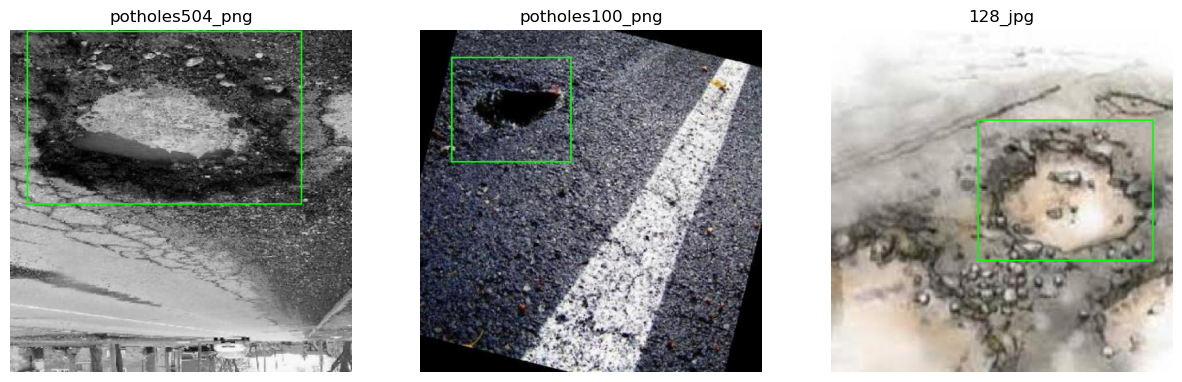

In [4]:
# We overlay a few labels to inspect the boxes against the images.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, r in zip(axes, random.Random(42).sample(records, 3)):
    with Image.open(r['path']) as im:
        im = im.convert('RGB')
    draw = ImageDraw.Draw(im)
    W,H = im.size
    for x,y,w,h in r['boxes']:
        draw.rectangle(((x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H), outline='lime', width=3)
    ax.imshow(im); ax.set_title(r['source']); ax.axis('off')
plt.show()


## 3. Checking exact duplicates and leakage in the original splits
We calculate a SHA-256 hash for each image to find files with identical bytes. We also check whether filename source groups or exact hashes appear in more than one original split.

These checks help me identify overlap without changing the original files. The final dataset retains all 3,940 images; the later split checks confirm that related filename groups stay together.


In [5]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
exact = defaultdict(list)
for r in records:
    r['sha256'] = sha256(r['path'])
    exact[r['sha256']].append(r)
duplicate_sets = [v for v in exact.values() if len(v) > 1]
print('Exact duplicate sets:', len(duplicate_sets))
print('Extra copies:', sum(len(v)-1 for v in duplicate_sets))
def leaking_groups(rows, key, split_key):
    groups = defaultdict(set)
    for r in rows:
        groups[r[key]].add(r[split_key])
    return {k: v for k,v in groups.items() if len(v) > 1}
print('Original source groups spanning splits:', len(leaking_groups(records, 'source', 'original_split')))
print('Original exact hashes spanning splits:', len(leaking_groups(records, 'sha256', 'original_split')))


Exact duplicate sets: 0
Extra copies: 0
Original source groups spanning splits: 385
Original exact hashes spanning splits: 0


## 4. Grouping the data for an 80/10/10 split
Here We shuffle the source groups with a fixed seed and allocate roughly 80% to training, 10% to validation and 10% to testing. We assign whole groups, so variants of one source cannot end up in different splits. Since groups contain different numbers of images, the image percentages can differ from the group percentages.

This cell produces a reproducible split proposal. To replay the completed cleaning process, We load the saved v2 manifest next. We do not have enough detail in the available logs to recreate the earlier transition from `split_manifest.csv` to v2, so We keep that distinction explicit.


In [6]:
groups = sorted({r['source'] for r in records})
random.Random(42).shuffle(groups)
a, b = int(.8*len(groups)), int(.9*len(groups))
proposal = {g: ('train' if i < a else 'valid' if i < b else 'test')
            for i,g in enumerate(groups)}
print('Proposal images:', Counter(proposal[r['source']] for r in records))

def load_manifest(name):
    with (ROOT / 'data' / name).open(newline='') as f:
        rows = list(csv.DictReader(f))
    assert len(rows) == len(records)
    assert len({r['image'] for r in rows}) == len(rows)
    assert {r['image'] for r in rows} == set(by_name)
    for r in rows:
        raw = by_name[r['image']]
        assert r['source'] == raw['source']
        assert r['original_split'] == raw['original_split']
        assert int(r['annotations']) == len(raw['boxes'])
        assert r['new_split'] in SPLITS
    assert not leaking_groups(rows, 'source', 'new_split')
    return rows
v2 = load_manifest('split_manifest_v2.csv')
v3 = load_manifest('split_manifest_v3.csv')
print('Recorded v2 images:', Counter(r['new_split'] for r in v2))


Proposal images: Counter({'train': 3162, 'valid': 402, 'test': 376})
Recorded v2 images: Counter({'train': 3180, 'test': 385, 'valid': 375})


## 5. Checking perceptual similarity and reviewing flagged pairs
We calculate a 64-bit pHash for each image using `hash_size=8`. We flag cross-split pairs with a Hamming distance of 5 or less, then display them side by side for review.

The hash helps me find visually similar images, including some that have different file bytes or source names. A flagged pair still needs visual review, and zero matches does not guarantee that every shared scene has been found.

For this run, We replay the recorded review decisions below and compare the result with v3. If We change the data or split proposal, We need to review the new flagged pairs before carrying those decisions forward.


In [7]:
for r in records:
    with Image.open(r['path']) as im:
        r['phash'] = int(str(imagehash.phash(im, hash_size=8)), 16)

def cross_split_pairs(assignments):
    # About 7.8 million cheap integer comparisons for this dataset.
    pairs = []
    for i, left in enumerate(records):
        for right in records[i+1:]:
            if assignments[left['image']] == assignments[right['image']]:
                continue
            distance = (left['phash'] ^ right['phash']).bit_count()
            if distance <= 5:
                pairs.append((left['image'], right['image'], distance))
    return pairs
v2_assignment = {r['image']: r['new_split'] for r in v2}
flagged = cross_split_pairs(v2_assignment)
print('v2 cross-split pHash pairs:', len(flagged))
for pair in flagged:
    print(pair)


v2 cross-split pHash pairs: 8
('10_jpg.rf.27be1fcbf1edc25b626cfbf193263641.jpg', 'potholes504_png.rf.4633b38088985f578083ee44d4a414f9.jpg', 2)
('10_jpg.rf.8d9f5bea5bf29dbe49a633bb9d6ab154.jpg', 'potholes504_png.rf.5ad6aaa6cdb4ae810732b13b9dd9900b.jpg', 2)
('10_jpg.rf.8d9f5bea5bf29dbe49a633bb9d6ab154.jpg', 'potholes504_png.rf.a975845d7e750a3732c9ea9da3a74757.jpg', 2)
('18_jpg.rf.0b529fb857198125af8e3ec396cae79e.jpg', 'potholes19_png.rf.70cb59c1e547d6f79ec85049fd20cac3.jpg', 2)
('18_jpg.rf.2f53e5de78f37bc2da064ba97891c9dc.jpg', 'potholes19_png.rf.c9c4670b52e1bf1bb36567c6cd481c98.jpg', 2)
('355_jpg.rf.5b5ce9ea0e882009f84d2cae3df26c33.jpg', 'potholes263_png.rf.79dd72dfafa60b2b022d36057891cea9.jpg', 4)
('55_jpg.rf.6cb9cdacad845bbc83375ae2101adf03.jpg', 'potholes641_png.rf.4483312a14ad8c92748057ea5c2954f9.jpg', 4)
('21_jpg.rf.9e6ffad2a228077cb840ae800ac0e2af.jpg', 'potholes618_png.rf.238a9426c3e5e6d1135e47792ce03792.jpg', 0)


cleaning-cell-13:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


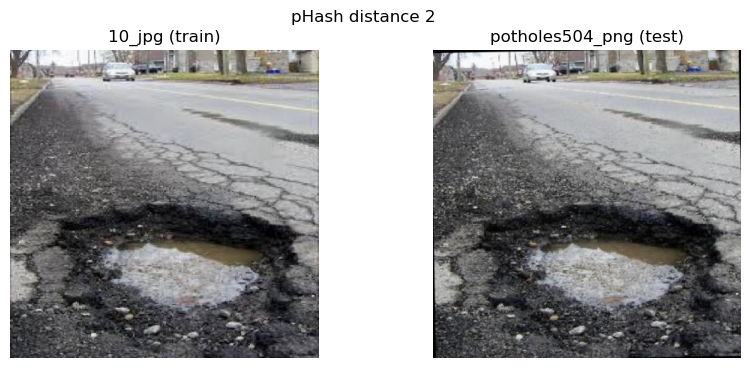

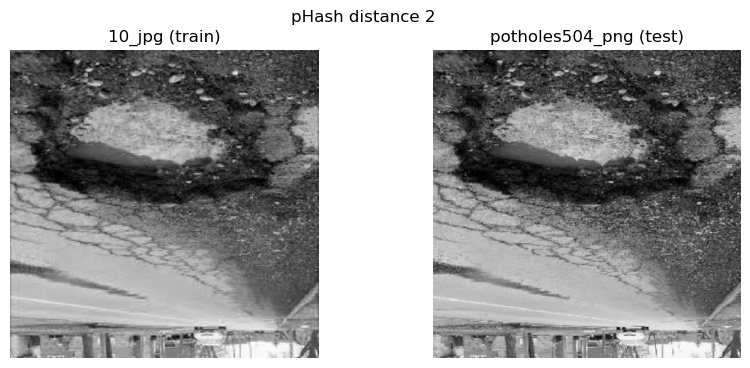

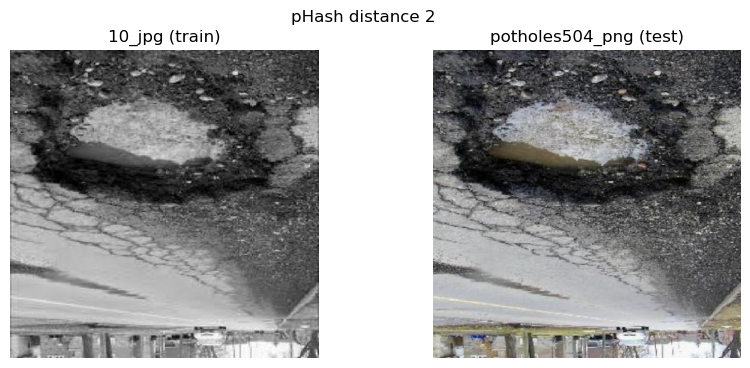

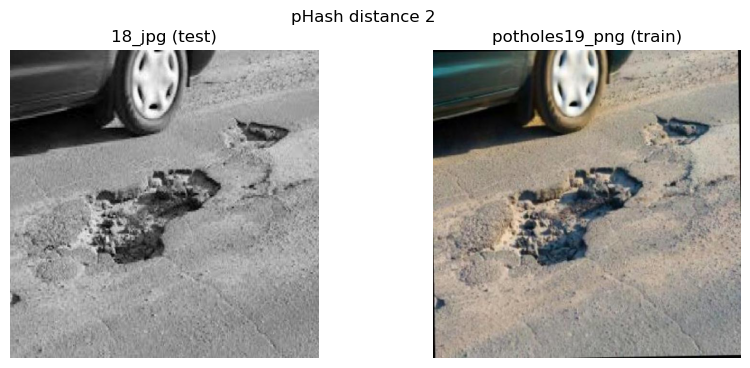

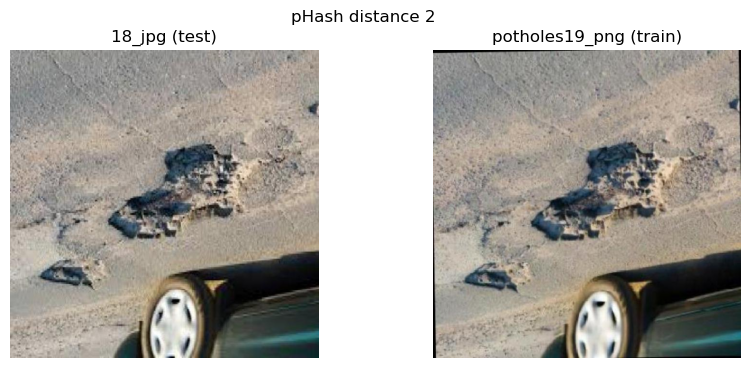

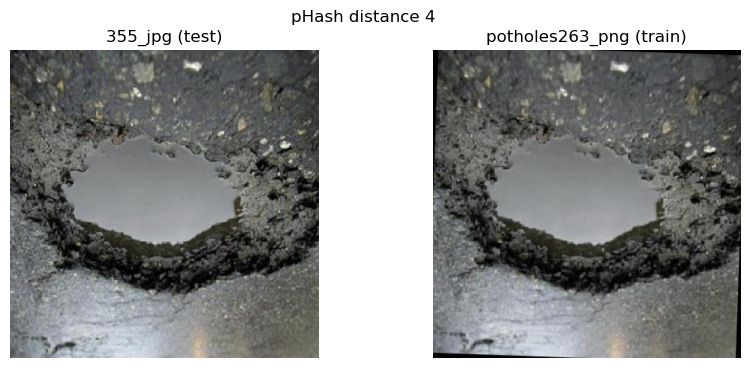

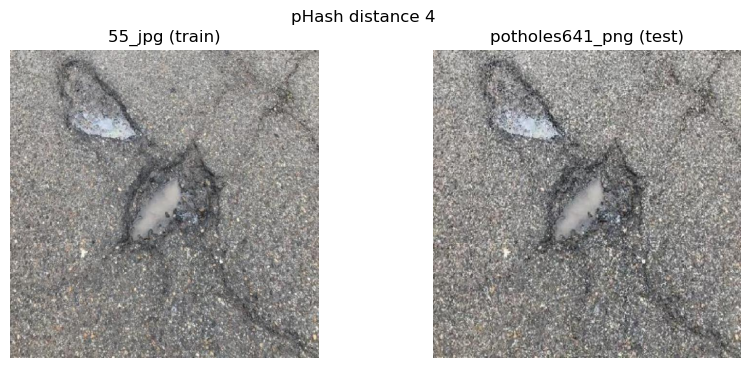

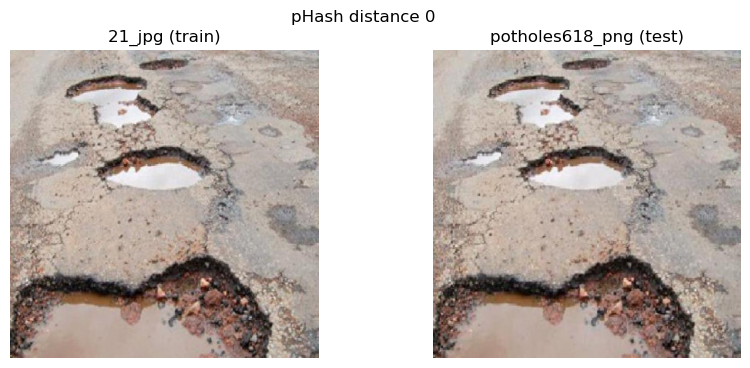

In [8]:
# We display the flagged pairs for visual review before replaying the recorded decisions.
for left, right, distance in flagged:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name in zip(axes, (left, right)):
        r = by_name[name]
        with Image.open(r['path']) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f"{r['source']} ({v2_assignment[name]})"); ax.axis('off')
    fig.suptitle(f'pHash distance {distance}')
    plt.show()


### Moving five test source groups to training
The v2 audit flagged eight cross-split pairs. The recorded review decision was to move **18_jpg, 355_jpg, potholes504_png, potholes618_png and potholes641_png** from test to train, affecting 16 images in total.

We apply that decision to whole source groups, then compare the resulting assignments with the v3 manifest. Validation stays at 375 images, while test decreases from 385 to 369. This cell replays the saved decision; it does not repeat the visual judgment automatically.


In [9]:
MOVED_GROUPS = {'18_jpg', '355_jpg', 'potholes504_png', 'potholes618_png', 'potholes641_png'}
assert len(flagged) == 8, 'Review changed inputs before replaying historical decisions'
final = []
for row in v2:
    row = dict(row)
    if row['source'] in MOVED_GROUPS:
        assert row['new_split'] == 'test'
        row['new_split'] = 'train'
    final.append(row)
assert sum(r['source'] in MOVED_GROUPS for r in final) == 16
assert {r['image']: r for r in final} == {r['image']: r for r in v3}
assignment = {r['image']: r['new_split'] for r in final}
assert not leaking_groups(final, 'source', 'new_split')
assert all(len({assignment[r['image']] for r in group}) == 1 for group in duplicate_sets)
final_pairs = cross_split_pairs(assignment)
assert not final_pairs, final_pairs[:10]
assert len(records) == 3940 and len(groups) == 834
assert sum(len(r['boxes']) for r in records) == 10111
EXPECTED = {'train': (3196, 8141), 'valid': (375, 1097), 'test': (369, 873)}
for split in SPLITS:
    subset = [r for r in final if r['new_split'] == split]
    actual = (len(subset), sum(int(r['annotations']) for r in subset))
    assert actual == EXPECTED[split], (split, actual)
    print(split, actual[0], 'images;', actual[1], 'boxes')
print('Source leakage: 0; cross-split pHash matches <=5: 0')


train 3196 images; 8141 boxes
valid 375 images; 1097 boxes
test 369 images; 873 boxes
Source leakage: 0; cross-split pHash matches <=5: 0


## 6. Creating a separate cleaned copy
We leave `WRITE_COPY = False` for the normal verification run. When We enable it, the copy step writes to `data/cleaned_notebook`, leaving `data/1`, the saved manifests and the existing `data/cleaned` unchanged.

Before copying, We check any existing destination files against the originals. Matching files can be reused on a rerun; a conflict stops the copy. We also write a YOLO YAML without an absolute dataset path, keeping the copy portable.

From the repository root, We can use the separate copy with `model.train(data="data/cleaned_notebook/data.yaml")`.


In [10]:
def copy_if_missing(source, target):
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists():
        assert sha256(source) == sha256(target), f'Existing output differs: {target}'
    else:
        shutil.copy2(source, target)

if WRITE_COPY:
    assert OUTPUT.resolve() == (ROOT / 'data/cleaned_notebook').resolve()
    assert not OUTPUT.is_symlink()
    # We check all destinations before starting the copy.
    jobs = []
    for r in final:
        raw = by_name[r['image']]
        for kind, source in [('images', raw['path']), ('labels', raw['label'])]:
            target = OUTPUT / r['new_split'] / kind / source.name
            assert OUTPUT.resolve() in target.resolve().parents, 'Unsafe output path'
            if target.exists():
                assert sha256(source) == sha256(target), f'Conflict: {target}'
            jobs.append((source, target))
    yaml_text = 'train: train/images\nval: valid/images\ntest: test/images\nnc: 1\nnames:\n  0: pothole\n'
    yaml_file = OUTPUT / 'data.yaml'
    if yaml_file.exists():
        assert yaml_file.read_text() == yaml_text, 'Existing YAML differs'
    for source, target in jobs:
        copy_if_missing(source, target)
    if not yaml_file.exists():
        yaml_file.write_text(yaml_text)
    print('Copied/verified', len(final), 'image-label pairs to', OUTPUT.name)
else:
    print('Read-only run: optional copy skipped.')


Read-only run: optional copy skipped.


## 7. Validating the cleaned files
Finally, We check that each split contains exactly the expected images and labels. We compare the copied files byte-for-byte with the originals, decode the images again and revalidate the annotations.

Because the image bytes match, the hash and leakage results above also apply to the cleaned files. We check the existing `data/cleaned` when it is present and the separate notebook copy if it has been created.


In [11]:
def validate_copy(folder):
    for split in SPLITS:
        rows = [r for r in final if r['new_split'] == split]
        expected_images = {r['image'] for r in rows}
        expected_labels = {by_name[r['image']]['label'].name for r in rows}
        assert {p.name for p in (folder/split/'images').iterdir() if p.is_file()} == expected_images
        assert {p.name for p in (folder/split/'labels').iterdir() if p.is_file()} == expected_labels
        count = 0
        for r in rows:
            raw = by_name[r['image']]
            image = folder/split/'images'/r['image']
            label = folder/split/'labels'/raw['label'].name
            assert sha256(image) == raw['sha256']
            assert sha256(label) == sha256(raw['label'])
            with Image.open(image) as im:
                im.load()
            count += len(read_boxes(label))
        assert (len(rows), count) == EXPECTED[split]
        print(folder.name, split, len(rows), 'images,', count, 'boxes: passed')

for folder in [ROOT/'data/cleaned', OUTPUT]:
    if folder.exists():
        validate_copy(folder)
    else:
        print(folder.name, 'not present; skipped')
print('FINAL DATASET VALIDATION PASSED')


cleaned train 3196 images, 8141 boxes: passed
cleaned valid 375 images, 1097 boxes: passed
cleaned test 369 images, 873 boxes: passed
cleaned_notebook not present; skipped
FINAL DATASET VALIDATION PASSED


## Final checks
We verify the expected v3 counts, replay the five-group correction and check that filename groups stay within one split. The final pHash audit checks for cross-split matches at distance 5 or less, while the file comparison confirms that the cleaned data matches the originals.

Filename grouping and pHash are still heuristics. We use them alongside visual review, rather than treating them as proof of scene independence or annotation quality. We keep the saved manifests as the record of the split decisions and reserve the test split for final evaluation.


## 5. Model choice and training configuration

Architecture: pretrained YOLO11s fine-tuned for one pothole class. The recovered original args.yaml records batch 16, 640 pixels, seed 0, patience 20, 100-epoch limit and optimizer auto. These are source-run settings. The exact resolved optimizer is not available from args.yaml alone. Team: explain CNN feature extraction, multi-scale detection, target assignment and box/class/DFL losses using the versioned implementation.

Supporting [cleaned-v3 training notebook](train_yollo_collab.ipynb) was restored from the supplied records. Earlier original-split notebook is [preserved here](notebooks/archive/train_original_split.ipynb). The existing training call below is displayed for inspection only, not executed by Run All:

```python
from ultralytics import YOLO
assert not (RUNS_DIR / RUN_NAME).exists(), "Run already exists. Skip to section 6 to evaluate, or choose a new RUN_NAME."
model = YOLO("yolo11s.pt")
train_results = model.train(
    data=str(DATA_YAML), epochs=100, imgsz=640, batch=16,
    patience=20, device=DEVICE, seed=0,
    project=str(RUNS_DIR), name=RUN_NAME,
)
BEST_WEIGHTS = Path(model.trainer.save_dir) / "weights/best.pt"
print("Best weights:", BEST_WEIGHTS)
```

## 6. Recovered training evidence

[Original settings](reports/original_cleaned_v3/training/args.yaml) · [Original results CSV](reports/original_cleaned_v3/training/results.csv). CSV contains 83 epochs, with highest validation mAP50–95 at epoch 63. Original source notebooks have no saved training outputs; the recovered run artifacts are the evidence.

![Original training curves](reports/original_cleaned_v3/training/results.png)

## 7. Validation and held-out evaluation

| Evidence | Precision | Recall | mAP50 | mAP50–95 |
|---|---:|---:|---:|---:|
| Original epoch 63 validation CSV | 77.770% | 66.653% | 73.841% | 41.528% |
| Reproduced validation | 77.813% | 66.545% | 73.820% | 41.527% |
| Reproduced held-out test | 78.966% | 67.946% | 77.123% | 48.406% |
| Previously reported test | 78.97% | 67.95% | 77.12% | 48.41% |

The test metrics reproduce the reported values to two decimal places. These are new CPU results from the fixed authenticated checkpoint, separate from original artifacts. Same Ultralytics 8.4.189; Python/PyTorch/device differ from the reported original T4 environment. Full [conditions](reports/verification_2026-10-27/evaluation_conditions.json), [metrics](reports/verification_2026-10-27/evaluation_metrics.json) and [console](reports/audit/2026-10-27/verification/evaluation_console_readable.log) are saved. No training or test-driven tuning was performed. Team: explain why the evaluator's P/R is not necessarily the CLI confidence threshold 0.25 operating point.

## 8. Successful predictions and failure examples

These are supplied original test-evaluation mosaics. They are qualitative examples, not newly counted matching results.

![Original test labels](reports/original_cleaned_v3/test_evaluation/val_batch0_labels.jpg)
![Original test predictions](reports/original_cleaned_v3/test_evaluation/val_batch0_pred.jpg)

Qualitative visual observations: the top-left tile has a plausible overlapping prediction at displayed confidence 0.9. The second top-row tile has three labelled boxes and two displayed predictions. The fourth tile shows a broad prediction and an extra lower box. Team: explain exact box matching and visual display limitations before labelling errors as TP/FP/FN. Do not generalize subgroup performance from these selected examples.

